# Week 12: Regression as a research method
Research Method of Data Science · Sogang University · Iegor Vyshnevskyi

**Thursday: 75-minute guided lab.** Run supplied code, inspect results, and write short interpretations. You are not expected to write these models from memory.

**Optional extension 9:** log outcomes, interactions, Elastic Net, and robust regression. These are outside the 75-minute core.

Start: save your own copy. In Colab use File > Save a copy in Drive. In JupyterLab use File > Save Notebook As. Run cells from top to bottom. At the end, restart the kernel/session and run all cells again.

**Today's question:** How is vehicle weight associated with city fuel economy, and how accurately can recorded vehicle characteristics predict it? These are separate research aims. Observational adjustment and good prediction do not establish a causal effect.

In [1]:
# 0. Setup: install only if a required package is missing.
# Colab normally includes these packages. A first-time local install needs internet.
import importlib.util, subprocess, sys
needed = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
          'matplotlib':'matplotlib', 'statsmodels':'statsmodels', 'sklearn':'scikit-learn'}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import io, json, base64, zlib, hashlib, platform, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import statsmodels, statsmodels.api as sm, statsmodels.formula.api as smf
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
SEED = 1201
OUT = Path('week12_regression_outputs')
for sub in ['raw','tables','figures']:
    (OUT/sub).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':125,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
BURGUNDY, BLUE = '#851a10', '#39758b'
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/'figures'/name, bbox_inches='tight')
    plt.show()
def save_table(table, name):
    table.to_csv(OUT/'tables'/name, index=False)
    display(table)
print('Ready. Python',platform.python_version(),'| statsmodels',statsmodels.__version__,'| sklearn',sklearn.__version__)

Ready. Python 3.13.4 | statsmodels 0.14.5 | sklearn 1.7.0


## 1. Source, variables, and an honest analysis sample · 8 minutes including setup
**Real data:** Quinlan, R. (1993), *Auto MPG*, UCI Machine Learning Repository, DOI [10.24432/C5859H](https://doi.org/10.24432/C5859H), CC BY 4.0. Revised StatLib data, 398 vehicle records, model years 1970–1982. UCI already removed eight original records with unknown MPG. Six of the remaining records lack horsepower.

Source: https://archive.ics.uci.edu/dataset/9/auto+mpg . The original data and metadata are embedded below, so running the lab does not require a live data download. The embedded text is an unchanged copy of the real source, not synthetic observations. Source file hashes are checked.

- `mpg`: city-cycle miles per gallon, higher means more distance per gallon.
- `weight`: pounds, rescaled to `weight_1000` for a readable coefficient.
- `horsepower`: engine horsepower. `?` means missing.
- `model_year`: two-digit year code. We add 1900 for display, but fit the recorded code.
- `origin`: categorical code. We retain codes 1, 2, 3 rather than assume a numerical ordering.
- `car_name`: label for inspecting records, excluded from prediction features.

The [ISLR2 authors' Auto documentation](https://search.r-project.org/CRAN/refmans/ISLR2/html/Auto.html) documents the weight unit. UCI supplies the raw files used here.

**Two routes:** explanatory OLS uses complete training records for its fixed variables. Prediction retains all training records and imputes horsepower within each cross-validation fold. We report these sample differences. Reserve 25% for the fixed final test comparison **before** plotting or fitting. This random split illustrates similar-record prediction, not future cars or new manufacturers.

In [2]:
# Embedded source copies. There is no need to edit the encoded text.
SOURCE_BLOBS = {'auto-mpg.data': 'eJydXduS4ziOfZ7+CkW/7HRsVI14F592f0W2VZnuki2vZGdl1tcvdSMOKciZMx3RExk1kadJEAQODiCWqL6XRVFU4V9Vuunn8I9Q5fqjMqX+vvypnP7Qhf8R//jz+Nq89V3b3Ivxp6Ztm+JSt+fD488/hCFQE5GENRHUerWCiu+GQA+P8/FnMfz8aOv+Z6FkGcBghcvP468RrtLKEhis8NZ+XLrH/bUY6ntY3/neBDQL+9U8mmL3W1+ORd8cmrYYhnsAcgAkI5AGIO1XoBL3+KPrT8W968/XLjGVlj7C+LhRrbQgmDKDeanb+v3cFKYcLaUJy8S9SVkSllnPsvD8WZ4vtwCZYtGepDCEFcyzYFW4vWj1H4/+ozifz9nCDC2MwHT4mdvkrbvez/WxONb34FvXOvUtT75FP6oqHCa3sPEA68uhHob61PXF6damaJWKaA7c3yp2Zafu9NIE16+D419fmr4YmmSjSoPjE5wtPS2O89X/Oj5O9fjbqW+UhAa+6qyg84St0nleggHDMuu+7b5wDqqsLLvb+V42wz3cpOJX/dJdi38Ov/768w85Q+rxN0Q0oA+IK7pyq58s+xkh1T/+vHcf3b0ujl3fXesQOsJ9H31FznfJFsktQMCKLqhhHe/0GO5NHyPHDBXvlncE5ZxmoUZXee36axMuuhQRRdIpVLAgU7kVxW5u6KV+a/pgvADkoqlgDVVFQGPYXYB0XE4w1am+D49rcWuNCG4hLYejbfxRVGq9TZIij/zHn29d+3MIp9dcx8MSxalpH+9N8NxTfQ24Bo6SNgrmsnSUDnFvzeOl6e4hCunUIyijjPdzhdHcNgNM/Tidw++URTukq6FAnTqWYVcz1PWh8L5JLCWWYywSP5VSQXIDjMPl13jaMjl+dCLYjtXV1sEXJ3rpm0uIW8EXS4oMlo2nVhiySu5FP6QpUxAyLXilDhGBXcsYED6K45RPBZdPpQCQKh6zwlsxh7yTHHPNYok8j/poWu1UREnC8Gs44wBx+s8uhOAuREXHTFEXjyicUXbPRRYn35qXOrjUuLXkHrAhTcoqOyqxDWkJkKdN/U8R/5GljsflI9B65rfz9T4GbU/xRxHRoEOXlpxYIUrqgJZgKOCLkmK/Vp410pZGFccQYbtLJEETKBA9WptSkgd9xh49BwpuoUbCxYECs1oYUfWJ7ZSsKhZqtN0lkI7AFNK0zvJZLWNaX0ljvk2OWEFSd8CFyFlFcg4ZFyoOffd4ea0v2QIp0Bm6jcLo7E6DyfZYJM+3dekt628c85Msv6oIzBvD7nYONoG+1Mdu4RrLf21jOgJzdJ+SY5h2eewe13tY2PB/j3PffIIZj8OMIYXDXI9jqH/U/XmFA4czZDwKrtLbPLiSw82UoxhuXX+vD8GUK8mSXIALyZhSalmxgSQLcMsi2QuW3oqcs6V7/hEMeDj3p2zD7GUVFFb0xvMuIZDU15ewRQWpOt7UymLQLbdBN+Bcmv44+tuxvoVjCJklywhL4CvSjCCk2qKFxN/dQoEXqokAstTAI4jz8TcdgJREH33cGvAhNfIhgAGzONhZac3WQgHmx7m+B2voQwARtBYRf9NSThLOqa0HpDmpbesp9QY4ykzgRZZ2KaxQlL0Bbsm8MwyfwG2JTFRvV5Uy0Ut3Gk0uRMpsBWdxQdFiZbZZ6DmOXHui7Z8WJtLloV8yhclr3Z/u3S3N5oFvrh6a+FSMPrNhRkAqFbv2DmiKM91YtcflxYgtVVxearr7x60pVAArufiQUG6MD4aWlsaHyHafXsO4SYtIRFmK/nGdolcSXfcSp8vVpXxhX0+cofJnsZ6LCHyOE7GEEgq3+Vzd2Eu+RIIULoxJvqgqsfIU1GACF5apG7NGRVQfxCVZkrhkFehwsLI1qIayPGTLYfckSUXQpswT2ww1SwdtM9SHHpij5D2DTkAby+J17Wm4dIdzYIwhcISLWlVF333UbbObzT2gSkk+klyE/mNom764Nr/G9DtDxlypiiQOoYagqEZRGEYu9e9TXfTvciQetyZ1Ov5sK88vDsjolrbwsm0gaXmNkl+sSLyP3TUssR84bE7ZDL6kKQZs/LmvrysJXwA/Z5TOsYvdLT1SurUp8OOqpVcqy60xir514c9Mw3AsgsI0bYTIUuImIGshVjgMpKyY4p3fhuRUTFmxIC1aLltLUXl2aX1zrR/tSCK4XbLxXXmzf7ZzfF+gyPZwHTyQUqitKB8Shwi1+wqlOGPhJTOl3R7jkqsfGxWRWSExryRjoy7AZ+wF6nOpoiy3eZHhX7YsmXtm2IQGmEveUBBSj831PsZoZbKq7auJQzGVLr8mTSqBp0NN1gSS81rH45IojqgYrnSpZXaqio0jX0jYylEIkYi1HmXwjzHmbdPPTtvFG95cWWbEIpxPPhDmoLKXvO2mIuYY1tuGRH4+ZgcC5AL6Q9SgSA5kMmJ7P30l/krl2INI2c50IotYjJvl+0NOmYxarJulTFt8dP3P8CMYEQ6GbxV5I1jcpUXRNsd7X4+/QYcNNrTcRVOV5DEzUgXLhLKXV9MEQVrWpG/hmtTXe6rM7ZTjVKlUvN9cu7ea9vuZ6hXydx7kab9r3+Pzyr7c2WLe91ARaKej48ucT2S2Wjs6n7c+fGz+STrJNEkPgY2Fs2ya+0QZgSPzt9b7nJzk1o8limSxLEU8X1o2SqFAte+wtCZrcsk3s9hCk4bH4dEfduk26HBhm+zKgG6/nYcxk/Uh7GXttR03c5XP0iu5WRSmoXjdSa0SmdIKA6m17qeiDinXnkomMsqVn+RSBQNLomLJQ3GuaEnk+kRtrCDxOS8dEsEgF2XVUjq8T6WDivVHTtiwDSZKCg65Sy09BGxiGQhX1EPSTrJOnqprbza9gxW7LUl6lokrAj1rFji5soilHLrEfhRPOajLXQzJkAfcQwnVEUVUP0s56/1ZpIIx1QXr9ef3sGE6Aksb1iCWVdZt/Yo2XGVqVBQkHRzjmNI5o02C5CUkijrVeQT1RAXw5Io5Rmitjp3VxKXYoqmy/FrWokk3X9FQlKKQkmTVpY9Y98TH0D64Jmhy2Vz+VdjtHUP5Yp7Zy6OR4drIqnTshVsiSRxCwB4pGy6VxSYN7A3CZXeZgwmsik1/4QLLLJjonfTHjiJgQ7HCnnhJUFlK/ryn6EuRpWS9ZQjmM+KiVK6Iaoa4pPI23SvruLy+5gCNAfcgs8kIDJaog5qcsoB9lmCpKPrvaO1V3NZKMvS+1o7tZEhLOD+i5SdWmtPS50TRVeITpKzbCoUGgnOdq1BnQEM/cwkqID8lxtBZ4L2dtJ6hOYTU/pJN7bGSlKApOb1x/LSU3FEygVz5vGOlocJYy+728f4YvqxwaZNHHr1bnjKg/KatqthL+gUdjtUItKRVGlzlVoCEpIjaigIWIHKKpCkV/ejek+u6d+ttPuqlczZ/qofX/dLAAY1UZT5MojcZFgMRVRWGOKSwmtnWdvYDgggYxUKqLsu8YZdENJdNtgDBSmiDzHuHqV+1aStsD6XME77OCQyEVp7ASG23NxBZ3/2Y5XlW6dObmmE2y2t3DZz4eH4bgxWuBgg6eJ/yYrujABMKorp/fCHjjI3k7eVa9/Muvvs0jVKww9QOg0cLiEmD3aICsLU7xngY0zGehcxzKp+doRxSOgb0NY2ZhPOPwxf98fUrUMBeFwZsWN7BEvOksCXqKRDoeQ+Prxu0ziljbqlxmrs+92mC2Qng2E/Bha0nOZcMo1C22xLU0Hjb5AMw2KzawWyV4iix8pHNpueX5Kl92gDyFykcFS5mNlTT7o/4P6ELTuWMzXyVLuANctTUTWASaTKlxry1SpUHFrTW8PPjtf71M9L18eiklRyQJNlLba21lKO/60L+t9xtppHmrITNR8fw6szzMfNkNKRcx4dxl5N2w/DStN9CdAKTtyVjuc2iVlGhBJPzRYTgo1+q/7CLwcRtfD5JmsaEerj3XZpbFFXH0Ntymxb1xj753CbkS8jdUuYc1uzyEqz82SF0o/OazWyIAI6yO8Gh+Eqz8Sk5Mc9uDOdrVK51bjbW14fD+b5XQwKukiKvRuj4b/Vxsg4cvuDuv7Q+b9GZjaLB9w9RQvQUbh2ipJPrbAvYI4zO2VY0z1sXuIs+tWnBh1oGdTOsYyJIqmUomA8ixzN0RYXz+fi7yYlScXw7HtNpOJL8sOmrN/PRFribEtlQdOR/VXIngC95woCJOr4UxpaxQRlyBRlj6yQ/TlGQlR+Bw4U8AoZxhJFQYgcmiWeUlC84Y6xoO9RSv7dTkh7NNYd3KndxVkLAIFEJO/pySf5sSsnnDeJ0q3NVCW0rA8ulClACp8DxVDiAfB46wmBTUnK7lt8rgtmW4/C9TyIYQL7F7300YW07aYjFMx1l8nGQ/DRm8rxE7fyjH3J3VQoQbWy2Q2h+zc2UJ1GyrAwLlHyDRIEbpH8oS2VJn/zI73LXze7jN5By3np2hWBsE+YiAprg0H513enj384o68LGkPkrZpJ/M9atLrApCsvPPMka8SQy1MNt7A42e0UYUBJl4tjiSr0z/67Dul5ez/UEZrZgibCG3Vg4u5XfvE1Mvi6Gv2PAyXh3oibTp7UOr17MusXpX+10ctEJHEdyRCXhDuPJbbkAqh2GdwOKVC4aDPTbbzLXO3YorgFbgSdsKK6N29tpBhoLgTm/wCnFnSklBJR4kZUgXdpElwJGYNISgG+UeA1hHB0gRriurfumuAXOfA4H+FZlXRy2PR/oLvkoJOSE8wCLw54JiSrSq3LLDbieiY2eKSxtE3JLhQwBbDXqDc2pGb4dmuvvsUkzRLQnDWtVwXcZGKPq0zm4wDHc5LfwQ7Or+GKH0eSTwxTvPorjxMD5Qg4+lK8cGCqPCT+CSb/iCs7kXwFiiDqJaXpfsPEbeGpJEWWpmBzEy/p4nMYNJnIInycIQUyoZK+cngOKg8J5onfn4fH7sXxOGiBZXddUbGip5rvnEnJlipf7zKTjJaZ+DlZ0oOmauFG8OXXfd7+Kl2HKMivYXozCOLxulGLUj2+iLF7r+/H1UE9i1g73A10FXRRW92zeiwbApeWyhS5trqvMoNB5PD7uI9446RIiRpPyPvA7uAECQ5Aj1OQzrIRIPr8NWnrwGk+AcaAgQNXJSJX7LE8ajB+aNecyyTxFbuJdRFFRR5Vw2rDA5AmKPY03YRWqzFhF5oNL9AaJl9moR3Yhc83LbdjFrpgKIRJKMjGHSJcQC5pyKNq/Uy/BgVSoNyzM9LEngJMYbUCvHwnuzlS+2lCNFXeZFRwDVndIN50oq56wVF6jg/Hur4/rqennb9d2BLUKI0LeMnI8BcJBhhiyaH0oRTid9xXSQwmhZlzeOh6z09fCxouFYLoab9uNbs8/7nPgwrAK8h+U0JCFDIb8TJOcJU5VsukIaunS5ELQ5uLG4gTC9E5jsXSwOLi4MLR9+dclyWz4dRq2F6ucTDpoEhWjmIOb49uKUIPreMl2tEB420LTZ4mg4lWCcV5KQdVEkgVkRX5WpoS8U9GSxlcNlCzPEWPUNSDVI4aT+WctLvms5Vsgj1pNG86qP11xFl7+i656eoGK07kZmnbiEBEanAofucB2rl6gI906j2+VTIVJtcDAmWE/12N/YYWJ+3xpj0Rr5v9/n0AEzywzWlPlQyrFy3u6OZgwKdnNWVzVVtwLqx7vwD5hUGozjlftEoa67a6Yk+ctb3gDdnmgipIEvvDV863tLvV9yseyYAgD9UGMy522SgjD0o1cq2o/4T3J70bBwcLK1jh7e+2a65L5kC1QhkqqapMH2SrPfEtnbNnpk/divM2jK3pufe7HJFr8s37cu7+maL06C0ZrzCgSSPDmJkS8S339K90qz2c08hk0XMpnonc87QDwUKMWMXG1KQ2X0115cpRQ6iUGSwdyhltzPI/f7AXA6ukJKLioSyWa+trv5vb6Mbcn49LAWKjdSLjygASS0gQjio1og6WxFrBDwRpqlm0WX35SdACvVTueynG0mbrmhwBPtmkNuOBl8yH0zUvd4mBv8c9wKIfur7j7J1c/EASilbDk2YEfo/iVlltsLNJlldcweBaX+uX6uBRTJAdmwBfQicwEMZOVUx3lY+g74oAfzq6u+2P6jvMdedIqTEaYXJEnmOk1nLA5v6KQhySEcfOqDtqpu1xnghCjzs6mRC4LpJtq2vMxJNA7Ek9FG0SxiTpjDktwOEIYDrwFH+smrKrYEm18Jwz7QLbg8l7gCP34lkUxvE+I0XC8+XWZ17SJ+UOw+TYBlVPDyEy2g4BGz05VqKmtQGtT05TwJfgsp9HLKfBWW1KyWwJZpEerX9rpHG3BkEUwuYds5AhmaUa+tPOriZJZjFJ8AKsIZRUbbamHNpGuoN5A1dkjnQbT4Ac8x3PfHY9dKmLvXGQFDgWULFHC2vfIiDcDJGRvqU2WZn1CKNomZNhh+kYiuM/zDCRhmwuf8EwGKuxUNKjiaf6vUFtXhJXmf51Sk52Evakl/TYPtdOyys9So7JlZnqfp8YRKHnygIBQWNU5v/F5MGZkNFtscw6M3TiZpzMwWns/UWZEJZocQ8UUpOAJI8Wd5Syz0FMKFaVwSGQKdEMMDwA4W264fx/T7XlWyX2xVWzgVQZl8+vkIWszDzomIhAILNTbLQ1MmuTuxj+yRKRF0sdwGMtsCXer5I44bY7T9/9xsVD87LVWEuBFWWqbUOt3Yz/617X437j+GV+JmBL2whXO36742N6MypDSMaPC6AV+VuBR2FiPPX4OlpSic6TORRLUsjE7g3snb9EsUjaJVy5WuJAssBdgNz0Oig/D7dyH/S4jMCPIlAHp2S9HqTRUZ7E5Vc6E1ye9oGLqBan5nUC+fwPu40uIgBgh1l5Q0566vj51KcnS9M4DdPZJ0JELsfHMrJDiym4MpTpWBmtH3uf0Y6/sVprWCBQOzkHiywAAHnnSa9eff3fXCcs8x4IWZhIicqziflTTlVh5F+QzcGNZUknk0Y1XljSRVBeTGiog+KSFyqmup5Gk4d6PDfbotxX5LcUsz/utRb9N35tuz5fzvTlNgGv+Fo74DrAm46FkgSAIOekcYut5PAJpP0NzKNjBEeRfk6GPKE5oxj0bfEAHfSQVQP78Q7P9RHz6RGidHkZVboY4KgpvMFCPIcnCV+zVArLVqe9jBGgn6Y5RABPHRd3DLIB7sjJdez76yhK/V9G0vMVtVf7S6J6jwSc5/JrQL6Lb7jA7FBQFoSXMbmo6qKfLUvSxyRJuF6BEiAkGiDIFDGMDjKrgCRxHMInaoWg1e5I5Prq5esJa/uj5BT9P5R3Un2BpJ8T29DfPt1HxqQQZiZSX3e/wAHGWgq20kxtFB4AaEb8xV9m8aupGJu0hKwmRvuIWlXxMLdltTgMv2sZCb8fBBYpxPt9eoBdTcowlMF+gb1T3xAPm4UpdfpYiYCkeN4UpQoMbsc0FWWJzgYtKReCJc0Phr6lZoZ/jUedQqgxv7uAAmrLEcIgq4fdDyRervkidfKzxB4SDKQzqDAGckviwBdyZbHhGj4QpmG71Bcyu0PmiN/KFwliM/YXAC8pi1BA0KUpwnvDZMTw4vlSgy+LWeY62OdY9sVeSbvjGnBQ4vwKXCBpzECAw30Bnp8J6HRb11jHja6v4iaNLVCJLTw4rmOQQrsW337OENAJlTz7gJxHECpeRkOQS9u/f3DysgjPkkksNBidf1ogednfvz4/L7bW49y62kBVpQJRn8LNxj8LWaqq833vsDv3cUotZi6bJcbJO5rN+iXPNmktKxKn2reCRDe1hi9N9zB777Jt18JeCH4qBgGVRB9KElU17SAOqouXiOwj+GoGWFNiHG53+BQmKxuKQ/GGnFYYfLCFylAHjBG+05BFM/8xoykeCtTOm5VAFX7Eo94zqadvMSOuqMPdouIuONz+9VxNI7W3y+8gi+c6oQ1VJ0JqSyDW9464kx0OSTzwthK2KsOJHopTt+USGJbuP+0oSWXG5vUxIa8HORytZmkzES20dWbFmW8dsy32dlRFZQ1tPMOt6ILvb5PPtTOvOT2ytCme0mForzk44kDhLyRU8At0Mx7FtpH9NUd0/R6JeYLiIjkeSr8lQOda9cFOSwY11TanS/HcoHuqshmYDqMJSpCKs+LVIdZ6WREZ3LNkTTHCJzn0LV/dxarIQzLJGZeCWgGfnrFFJrueR/OUCeZsn8/DAY94nck1thpKzNgTgCv0byLWsoNPNyU9Komq02ieRZsxQTH1HGiQpKbdTlxSKWyVwoNIW6AdvhLNIWjlHoG+hpMcifsUBm/fNMJxP88clsZtCZA/shjPXijF6NYaV+v18md+qoiY8++GrFmbrm9vPhJccmqts0IZ3+VjiAsQoWu2wOwiBD8hZiHmiSO9y/IqijXJ+VpliR1/brM8Tk2im805aW/ZCPEuwQJJe3GLzgG49fnk0DXa5T9E0VPJP0Wb2MAWdTzDhqdaFJe9iym+nbvxyC549QFAsgl0eqdNHtP8eH0YohgarWBik3GElRuZJCR9anVnT0KSG5AUWp/hNb1Qt/PCW/9iwsjkpgaduY99snT/Aj0xpaZAEVJn/tUsVPd9MzbNkPp5PTSGHQzpRCxI7NtcmLIWnBLLEcfv1TBNKsEzftYmH7BEMB7fW7qNNmiCzUWQZyfMlDk4zZxmX+c1BxX/9WbKILpoOmnHtx/W9yA6B/2ZYYOtsPc6wz+t5GMaHUENR9Lsusg8e9hI7FliAlZZEeOUhr6Pur83ibSsj514ZTiy/owAkQ2hlvqLlkzr4rusrMI6FiZNsX1iUZ4JPosFO85OSHp8QFTsBm3zKAVc7e8Jp1fsVfPBnubCoSgFuBWGHyX3HEHBr0HbwsRq+pjQV4x1c8ro0p7ptZ/EYvnWF1xfwFT8VfSW5W0l2bZNDHnX+dX0g/1v8VI7xunXUJ70JO/WpA2qzyQShDOzHv0xRfpdfSQZ+UzRtM+Cl7rsUC7R2fBwC1QbI0IkGMslh8JwS/NUdcJ7Uu5I6Qs1C4i343+OWGp03lMQOE6xnNlQfyuWQB1IiA8wbOmk2/9gKNxbc4KXJiUEsBCrYlMO2Hlyp+Ru54duo2f4/3JXRPA==', 'auto-mpg.names': 'eJx9VE1v2zgQvetXDHyKAZtA4jaNdUvTHtqtd9sk7Z2ixhJRivTyw17/+32kLdtt2howQIrDN/PezOO1oGcdDdd0n6KbrzYdvZNRVtWNoCeXvOJQV0R0Jaf0j9edtjXRc68DtQgLHGknA0X5nS2tvRso9kxPUcZPuiGjGy/9nna9Vj3pkIF++A1S24g/tyQjPUhvudNMKzbGWfpq9ZZ90HGPIgF7mfEFVAoA0bbkv17eLeh+YK+VtKUaHSLWhu5DcEpjD/j3/20cwLEUhaGaZupQ4mMye3ozA8xyUVULQZ9liPQ1yI6LFjQnemKmmwayNG7L0/Hrl6StkXb2KOgq354KenBDo622HX2wIUqreP5W5lqlbWnlWjbH/ScGfcSJkdoHS5+9U8wtvgZyB27PbGOPs8jeFh5g9eDsmj0Dm9yaVlL1kPQk0Qg8o5vF7fzm1WJ2oezhQgi4AwVjDDMI1+MsClTnO2lHmL9kWg/SQqzqlaBHNryVNqKStfNDqaSucuwPw4GlpGB010doOrhWrzW4luQghOTxorEb77a6LX3MSL8YJVFkMZneTkOHHIK6qdnTowthbMBR/SPOxkNCFXMPcryM0esmRabJsOkmM7ob63BlwCGoPrYq0A66kucBXW6Log0rmTMifk+9bCnZ79btLG2lSbgANQpWwT7nElRG+JQhQ12KtJXayMbwOMJrjfVEZk8CSOTQ+Xh5IorQk9ETpBxq9TaQQkfnaq9wd53Y5IOQhk0ZdwAPAA20YU+dzA6bld5GB1KjSEcTsR9CVmVBQzJRF24ttToozxAuz+7rjA5Rk0sHY5+4BjGhq9EKxUXTqnot6O80NMgN2NEKoabF8q6qbi8P7084NS1RjTKpHXunDGb1nKmq3ohz/MtZpGtBkK++eCd+KhrPnNpjnlpM5CGsEJ7/xLjE4iXAfmOk4gEurF+AwRe984E3DmNT/yIbRNhxNkP9m3IghFQK3vIHFi8CwHfIjwbt4er6z/XeieO8nbL9PnYJHaQnKwc+RgeoCtWvktX/Ji5zzTI/48feoadIsNIh5LBzE74VHwDkLAV8EugW43eIPTilqv4HmOkV7g=='}
SOURCE_MANIFEST = {'url': 'https://archive.ics.uci.edu/static/public/9/auto+mpg.zip', 'dataset_page': 'https://archive.ics.uci.edu/dataset/9/auto+mpg', 'doi': '10.24432/C5859H', 'license': 'CC BY 4.0', 'retrieved_utc': '2026-11-13T00:15:55.298499+00:00', 'sha256': {'auto-mpg.data': '48b830e11feee5572525f8f1691ddb9d38d3d7b7063edcd8fca672c2a5e17d8d', 'auto-mpg.names': 'f6ac336f3b11955d71adee2100faf30f8c1be20e6727476836d437d35804599c'}}
for filename, encoded in SOURCE_BLOBS.items():
    content = zlib.decompress(base64.b64decode(encoded))
    assert hashlib.sha256(content).hexdigest() == SOURCE_MANIFEST['sha256'][filename]
    (OUT/'raw'/filename).write_bytes(content)
(OUT/'raw'/'source_manifest.json').write_text(json.dumps(SOURCE_MANIFEST, indent=2))
columns = ['mpg','cylinders','displacement','horsepower','weight','acceleration','model_year','origin','car_name']
data = pd.read_csv(OUT/'raw'/'auto-mpg.data', sep=r'\s+', names=columns, na_values='?', quotechar='"')
data.insert(0,'record_id',np.arange(1,len(data)+1))
data['weight_1000'] = data['weight']/1000
assert len(data)==398 and data['horsepower'].isna().sum()==6
assert data['mpg'].gt(0).all() and data['origin'].isin([1,2,3]).all()
train_ids, test_ids = train_test_split(data.index, test_size=0.25, random_state=SEED)
train = data.loc[train_ids].sort_index().copy()
test = data.loc[test_ids].sort_index().copy()
assert set(train.index).isdisjoint(test.index)
OLS_VARS = ['mpg','weight_1000','horsepower','model_year','origin']
analysis = train.dropna(subset=OLS_VARS).copy()
flow = pd.DataFrame({'sample':['Raw','Training','Reserved test','Complete-case OLS training'],
                     'n':[len(data),len(train),len(test),len(analysis)]})
save_table(flow,'sample_flow.csv')
display(train[['mpg','weight','horsepower','model_year']].describe().round(2))
display(train[['mpg','weight','horsepower','model_year']].isna().sum().rename('missing_training'))
display(train[['record_id','car_name','mpg','weight','horsepower']].head())
train.to_csv(OUT/'training_records.csv', index=False)
print('OLS drops',len(train)-len(analysis),'training rows with missing required variables.')

,sample,n
0,Raw,398
1,Training,298
2,Reserved test,100
3,Complete-case OLS training,294


,mpg,weight,horsepower,model_year
count,298.00,298.00,294.00,298.00
mean,23.05,3031.63,107.97,75.80
std,7.78,865.53,40.16,3.72
min,9.00,1613.00,46.00,70.00
25%,16.50,2268.25,80.00,73.00
50%,22.00,2862.50,95.00,76.00
75%,28.00,3732.50,139.75,79.00
max,44.30,4997.00,230.00,82.00


mpg           0
weight        0
horsepower    4
model_year    0
Name: missing_training, dtype: int64

,record_id,car_name,mpg,weight,horsepower
0,1,chevrolet chevelle malibu,18.0,3504.0,130.0
1,2,buick skylark 320,15.0,3693.0,165.0
2,3,plymouth satellite,18.0,3436.0,150.0
4,5,ford torino,17.0,3449.0,140.0
5,6,ford galaxie 500,15.0,4341.0,198.0


OLS drops 4 training rows with missing required variables.


**Checkpoint 1.** How many records enter each route? Why is `origin` a category? Why would deleting all zero-valued observations be an inappropriate generic cleaning rule?

**Your answer:** ...

## 2. Simple and adjusted OLS · 12 minutes
OLS means *ordinary least squares*. It chooses coefficients to minimize the sum of squared residuals. A residual is observed MPG minus fitted MPG.

Simple specification: `mpg ~ weight_1000`.
Adjusted specification: `mpg ~ weight_1000 + horsepower + model_year + C(origin)`.

`C(origin)` creates indicator variables, with code 1 as the reference. Both models use the **same complete training rows**, so a coefficient change is not caused by switching samples. All coefficients here describe conditional associations.

,term,estimate,SE,CI_low,CI_high,p_value
0,Intercept,-17.323201,4.600236,-26.377548,-8.268854,2.013259e-04
1,C(origin)[T.2],2.125837,0.834619,0.483111,3.768563,1.138319e-02
2,C(origin)[T.3],1.858322,0.629545,0.619229,3.097416,3.418711e-03
3,weight_1000,-5.613336,0.487948,-6.573734,-4.652939,1.877119e-25
4,horsepower,-0.005340,0.010493,-0.025993,0.015313,6.112092e-01
5,model_year,0.755296,0.057484,0.642154,0.868438,3.243375e-31


,model,n,weight_coef,R_squared_training
0,Simple,294,-7.475549,0.701006
1,Adjusted,294,-5.613336,0.826824


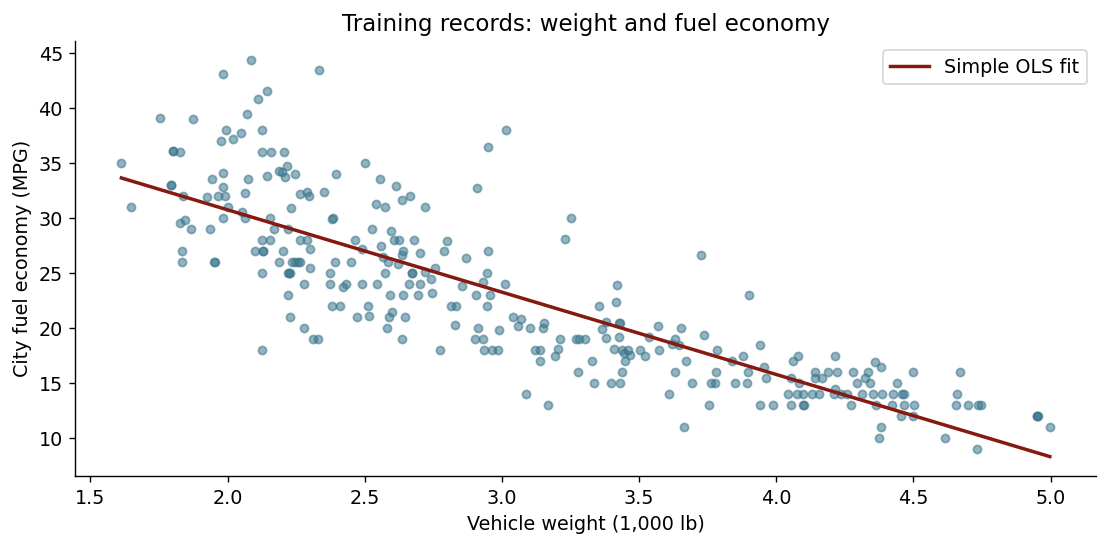

Raw conventional and HC3 coefficients agree: True


In [3]:
m1 = smf.ols('mpg ~ weight_1000', data=analysis).fit()
m2 = smf.ols('mpg ~ weight_1000 + horsepower + model_year + C(origin)', data=analysis).fit()
# HC3 changes the estimated covariance matrix, not the OLS coefficient estimates.
m2hc = m2.get_robustcov_results(cov_type='HC3', use_t=True)
def coef_table(result):
    names = result.model.exog_names
    ci = np.asarray(result.conf_int())
    return pd.DataFrame({'term':names, 'estimate':np.asarray(result.params),
        'SE':np.asarray(result.bse), 'CI_low':ci[:,0], 'CI_high':ci[:,1],
        'p_value':np.asarray(result.pvalues)})
def term_row(result, term):
    return coef_table(result).set_index('term').loc[term]
save_table(coef_table(m2hc),'adjusted_OLS_HC3.csv')
comparison = pd.DataFrame([
    {'model':name,'n':int(model.nobs),'weight_coef':term_row(model,'weight_1000')['estimate'],
     'R_squared_training':model.rsquared} for name,model in [('Simple',m1),('Adjusted',m2)]])
save_table(comparison,'OLS_comparison.csv')
fig,ax=plt.subplots(figsize=(9,4.5))
ax.scatter(analysis.weight_1000,analysis.mpg,s=22,alpha=.55,color=BLUE)
grid=pd.DataFrame({'weight_1000':np.linspace(analysis.weight_1000.min(),analysis.weight_1000.max(),150)})
ax.plot(grid.weight_1000,m1.predict(grid),color=BURGUNDY,lw=2,label='Simple OLS fit')
ax.set(xlabel='Vehicle weight (1,000 lb)',ylabel='City fuel economy (MPG)',title='Training records: weight and fuel economy')
ax.legend();savefig('01_simple_OLS.png')
print('Raw conventional and HC3 coefficients agree:',np.allclose(m2.params,m2hc.params))

**Checkpoint 2.** Write an interpretation of the adjusted `weight_1000` coefficient, including its unit, controls, interval, and population boundary. Compare it with the simple coefficient. Does adjustment prove that reducing a car's weight would cause this change?

**Your answer:** ...

## 3. Functional form and residual evidence · 12 minutes
A straight line may miss curvature. A quadratic adds a squared term while retaining a linear model in its coefficients. We center weight at 3,000 lb so the linear term is the local slope there.

The marginal slope in the quadratic is `b_weight_c + 2*b_weight_c_squared*weight_c`. One coefficient alone no longer describes every weight change.

HC3 addresses unequal error variance under an independent-record approximation. It does not repair omitted variables, a poor functional form, or dependence among related vehicle models.

,term,estimate,SE,CI_low,CI_high,p_value
0,Intercept,-38.048322,4.524074,-46.952894,-29.143751,1.946811e-15
1,C(origin)[T.2],1.428302,0.776234,-0.099531,2.956135,6.679472e-02
2,C(origin)[T.3],0.609180,0.598220,-0.568275,1.786635,3.093829e-01
3,weight_c,-6.497487,0.450799,-7.384779,-5.610195,8.350461e-36
4,I(weight_c ** 2),2.177271,0.269717,1.646397,2.708146,1.908706e-14
5,horsepower,-0.014529,0.009449,-0.033128,0.004070,1.252550e-01
6,model_year,0.803265,0.056598,0.691865,0.914665,5.324890e-35


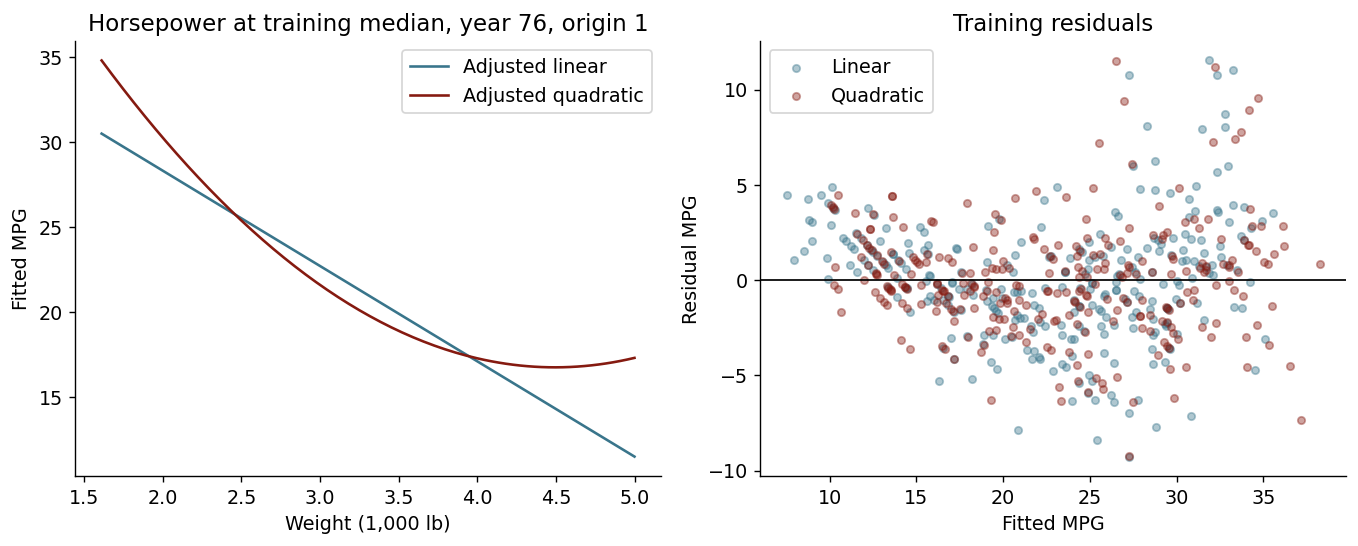

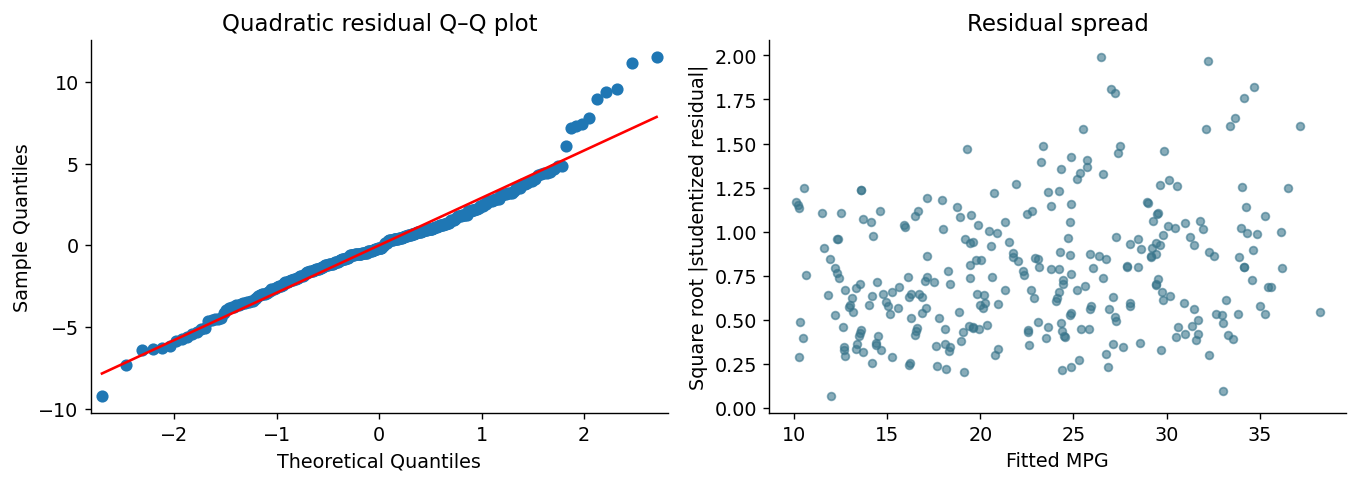

,term,conventional_SE,HC3_SE
0,Intercept,4.694892,4.600236
1,C(origin)[T.2],0.620237,0.834619
2,C(origin)[T.3],0.596234,0.629545
3,weight_1000,0.491692,0.487948
4,horsepower,0.010167,0.010493
5,model_year,0.057763,0.057484


In [4]:
analysis['weight_c'] = analysis['weight_1000']-3
m3 = smf.ols('mpg ~ weight_c + I(weight_c**2) + horsepower + model_year + C(origin)',data=analysis).fit()
m3hc = m3.get_robustcov_results(cov_type='HC3',use_t=True)
save_table(coef_table(m3hc),'quadratic_OLS_HC3.csv')
# This curve fixes other predictors for an illustrative conditional comparison.
curve=pd.DataFrame({'weight_1000':grid.weight_1000,'horsepower':analysis.horsepower.median(),
                    'model_year':76,'origin':1})
curve['weight_c']=curve.weight_1000-3
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
axes[0].plot(curve.weight_1000,m2.predict(curve),label='Adjusted linear',color=BLUE)
axes[0].plot(curve.weight_1000,m3.predict(curve),label='Adjusted quadratic',color=BURGUNDY)
axes[0].set(xlabel='Weight (1,000 lb)',ylabel='Fitted MPG',title='Horsepower at training median, year 76, origin 1')
axes[0].legend()
for model,color,label in [(m2,BLUE,'Linear'),(m3,BURGUNDY,'Quadratic')]:
    axes[1].scatter(model.fittedvalues,model.resid,alpha=.4,s=18,color=color,label=label)
axes[1].axhline(0,color='black',lw=1)
axes[1].set(xlabel='Fitted MPG',ylabel='Residual MPG',title='Training residuals')
axes[1].legend();savefig('02_form_and_residuals.png')
# Diagnostic plots describe residuals, not assumptions about X being normal.
fig,axes=plt.subplots(1,2,figsize=(11,4))
sm.qqplot(m3.resid,line='s',ax=axes[0]);axes[0].set_title('Quadratic residual Q–Q plot')
axes[1].scatter(m3.fittedvalues,np.sqrt(np.abs(m3.get_influence().resid_studentized_internal)),s=20,alpha=.6,color=BLUE)
axes[1].set(xlabel='Fitted MPG',ylabel='Square root |studentized residual|',title='Residual spread')
savefig('03_residual_diagnostics.png')
se_comparison=pd.DataFrame({'term':m2.model.exog_names,'conventional_SE':np.asarray(m2.bse),'HC3_SE':np.asarray(m2hc.bse)})
save_table(se_comparison,'conventional_vs_HC3.csv')

**Checkpoint 3.** Describe one pattern you see in the plots. Why might a curve improve the model? Why can HC3 fail to fix the same problem? Which plotted weight/horsepower combinations may have little observed support?

**Your answer:** ...

## 4. Influential records and a transparent sensitivity check · 10 minutes
A large residual, unusual predictor combination (*leverage*), and strong influence are different. Cook's distance summarizes how much a fitted model changes when a record is left out. We inspect its largest value, then report a leave-one-out sensitivity result. A large value alone does not justify deleting a valid record.

,record_id,car_name,weight_1000,mpg,leverage,studentized_residual,cooks_distance
326,327,vw dasher (diesel),2.335,43.4,0.032629,3.870342,0.072179
327,328,audi 5000s (diesel),2.950,36.4,0.042397,3.273548,0.067778
325,326,vw rabbit c (diesel),2.085,44.3,0.033060,3.322223,0.053910
244,245,volkswagen rabbit custom diesel,1.985,43.1,0.032394,3.091284,0.045703
332,333,vokswagen rabbit,1.845,29.8,0.042953,-2.559691,0.042009


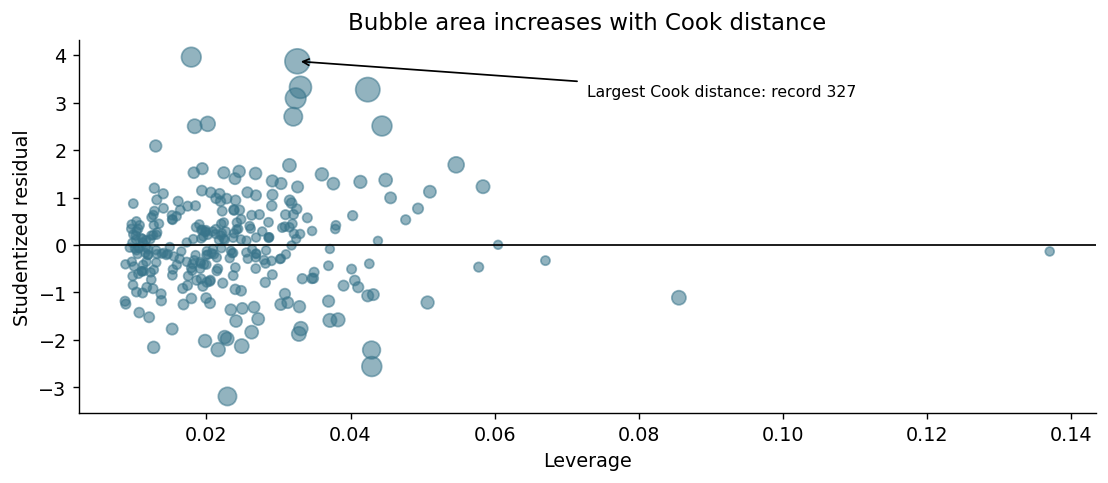

,specification,n,slope_at_3000_lb,CI_low,CI_high
0,All complete training rows,294,-6.497487,-7.384779,-5.610195
1,Leave out largest Cook record (sensitivity only),293,-6.594974,-7.472809,-5.717140


In [5]:
influence=m3.get_influence()
diag=analysis[['record_id','car_name','weight_1000','mpg']].copy()
diag['leverage']=influence.hat_matrix_diag
diag['studentized_residual']=influence.resid_studentized_internal
diag['cooks_distance']=influence.cooks_distance[0]
top_index=diag.cooks_distance.idxmax()
save_table(diag.nlargest(5,'cooks_distance'),'influence_top5.csv')
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(diag.leverage,diag.studentized_residual,s=25+2500*diag.cooks_distance,color=BLUE,alpha=.55)
ax.annotate('Largest Cook distance: record '+str(diag.loc[top_index,'record_id']),
            (diag.loc[top_index,'leverage'],diag.loc[top_index,'studentized_residual']),xytext=(.50,.85),textcoords='axes fraction',fontsize=9,arrowprops={'arrowstyle':'->','color':'black'},bbox={'facecolor':'white','edgecolor':'none','alpha':.8})
ax.axhline(0,color='black',lw=1);ax.set(xlabel='Leverage',ylabel='Studentized residual',title='Bubble area increases with Cook distance')
savefig('04_influence.png')
m3_leave=smf.ols(m3.model.formula,data=analysis.drop(index=top_index)).fit(cov_type='HC3',use_t=True)
# At 3,000 lb, weight_c = 0 and the local quadratic slope equals its linear term.
sensitivity=pd.DataFrame([
 {'specification':label,'n':int(mod.nobs),'slope_at_3000_lb':term_row(mod,'weight_c')['estimate'],
  'CI_low':term_row(mod,'weight_c')['CI_low'],'CI_high':term_row(mod,'weight_c')['CI_high']}
 for label,mod in [('All complete training rows',m3hc),('Leave out largest Cook record (sensitivity only)',m3_leave)]])
save_table(sensitivity,'influence_sensitivity.csv')

**Checkpoint 4.** Identify the flagged car and compare estimates. Is there evidence of a source error? Explain why both results should remain visible even if you prefer one specification.

**Your answer:** ...

## 5. From econometric interpretation to prediction · 18 minutes
**Predictive question:** Which prespecified model predicts MPG best for records similar to this historical sample?

We compare a training-mean baseline, a linear model with original features, and quadratic feature expansions fitted with OLS, Ridge, and Lasso. A polynomial expansion creates squares and interactions from the six numerical predictors. Origin enters as two indicator variables. Car names and record IDs are excluded.

- **Ridge:** an L2 penalty shrinks coefficients, often useful with correlated predictors.
- **Lasso:** an L1 penalty can set coefficients to zero. Retained features are predictive selections, not proven causes.
- **alpha:** penalty strength in scikit-learn. Choose it with five-fold cross-validation using only the training set.

The complete preprocessing **Pipeline** goes inside **GridSearchCV**. Every fold learns its own imputation and scaling. A scaler placed outside an internally cross-validated Lasso can leak validation information. We avoid that pattern here.

The prediction route uses all training rows, imputing missing numerical predictors using the fold's training median. Its sample therefore differs slightly from explanatory complete-case OLS. **All predictive candidates use the same folds and final test rows.**

,model,CV_RMSE,alpha
0,Mean baseline,7.782543,NaN
1,Linear OLS,3.245577,NaN
2,Expanded OLS,3.065698,NaN
3,Ridge,2.790761,0.231013
4,Lasso,2.764604,0.003981


Training-CV selection frozen before test evaluation: Lasso


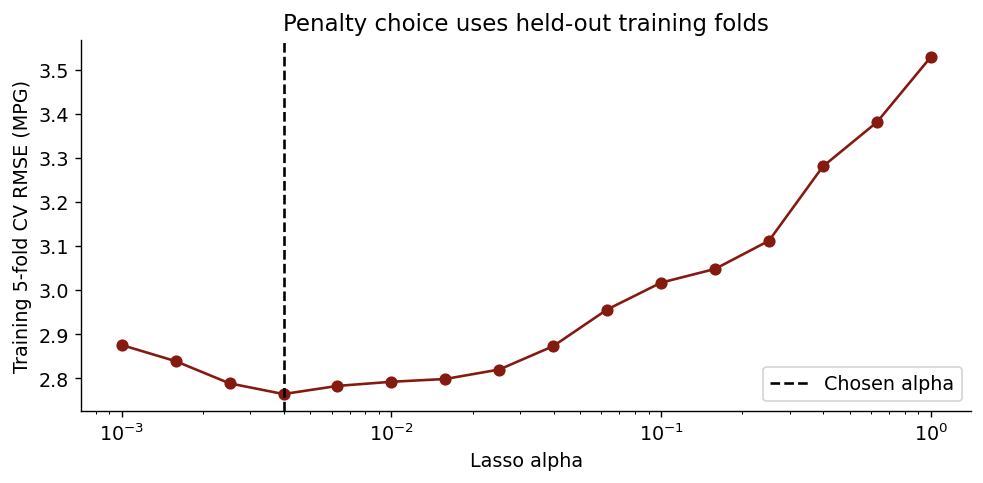

In [6]:
NUM=['cylinders','displacement','horsepower','weight','acceleration','model_year']
CAT=['origin'];FEATURES=NUM+CAT
X_train,y_train=train[FEATURES],train.mpg
X_test,y_test=test[FEATURES],test.mpg
cv=KFold(n_splits=5,shuffle=True,random_state=1202)
def prediction_pipeline(model,degree=2):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median')),
                      ('poly',PolynomialFeatures(degree=degree,include_bias=False))])
    prep=ColumnTransformer([
      ('num',numeric,NUM),
      ('cat',OneHotEncoder(categories=[[1,2,3]],drop='first',handle_unknown='error',sparse_output=False),CAT)])
    return Pipeline([('features',prep),('scale',StandardScaler()),('model',model)])
candidates={
 'Mean baseline':(DummyRegressor(strategy='mean'),{}),
 'Linear OLS':(prediction_pipeline(LinearRegression(),degree=1),{}),
 'Expanded OLS':(prediction_pipeline(LinearRegression()),{}),
 'Ridge':(prediction_pipeline(Ridge()),{'model__alpha':np.logspace(-2,3,12)}),
 'Lasso':(prediction_pipeline(Lasso(max_iter=100000,tol=1e-5)),{'model__alpha':np.logspace(-3,0,16)})}
searches={};cv_rows=[]
for name,(estimator,grid_params) in candidates.items():
    search=GridSearchCV(estimator,grid_params,cv=cv,scoring='neg_mean_squared_error',n_jobs=1,error_score='raise')
    search.fit(X_train,y_train)
    searches[name]=search
    cv_rows.append({'model':name,'CV_RMSE':np.sqrt(-search.best_score_),
                    'alpha':search.best_params_.get('model__alpha',np.nan)})
cv_results=pd.DataFrame(cv_rows)
winner=cv_results.loc[cv_results.CV_RMSE.idxmin(),'model']
save_table(cv_results,'training_CV_comparison.csv')
print('Training-CV selection frozen before test evaluation:',winner)
# The following curve uses training CV only, never test scores.
lsearch=searches['Lasso']
cv_trace=pd.DataFrame(lsearch.cv_results_)
fig,ax=plt.subplots(figsize=(8,4))
ax.semilogx(cv_trace['param_model__alpha'].astype(float),np.sqrt(-cv_trace['mean_test_score']),marker='o',color=BURGUNDY)
ax.axvline(lsearch.best_params_['model__alpha'],color='black',linestyle='--',label='Chosen alpha')
ax.set(xlabel='Lasso alpha',ylabel='Training 5-fold CV RMSE (MPG)',title='Penalty choice uses held-out training folds')
ax.legend();savefig('05_lasso_CV.png')

,feature,coefficient,retained
0,num__cylinders,0.000000,False
1,num__displacement,-0.000000,False
2,num__horsepower,0.000000,False
3,num__weight,-0.000000,False
4,num__acceleration,-6.151710,True
5,num__model_year,-6.104260,True
6,num__cylinders^2,-2.480183,True
7,num__cylinders displacement,-0.000000,False
8,num__cylinders horsepower,0.000000,False
9,num__cylinders weight,4.650737,True


Lasso retains 18 of 29 expanded features.


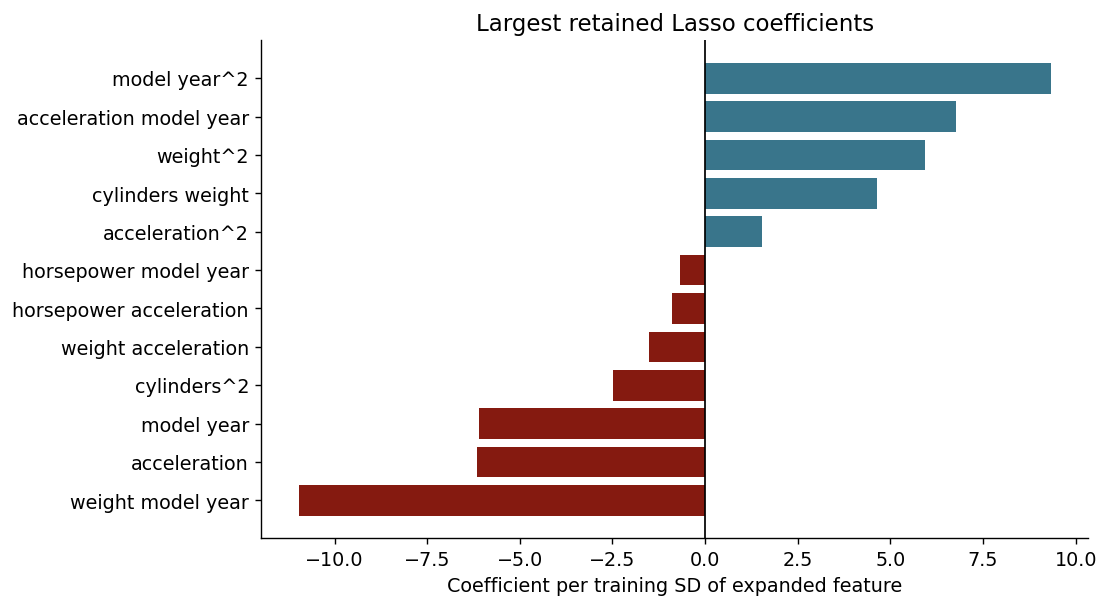

In [7]:
# Coefficients refer to standardized expanded features, not to unscaled pounds.
lasso_fit=searches['Lasso'].best_estimator_
feature_names=lasso_fit.named_steps['features'].get_feature_names_out()
lasso_coefs=pd.DataFrame({'feature':feature_names,'coefficient':lasso_fit.named_steps['model'].coef_})
lasso_coefs['retained']=np.abs(lasso_coefs.coefficient)>1e-8
save_table(lasso_coefs,'lasso_standardized_coefficients.csv')
print('Lasso retains',int(lasso_coefs.retained.sum()),'of',len(lasso_coefs),'expanded features.')
nonzero=lasso_coefs.loc[lasso_coefs.retained].copy()
shown=nonzero.loc[nonzero.coefficient.abs().nlargest(12).index].sort_values('coefficient')
fig,ax=plt.subplots(figsize=(9,5))
labels=shown.feature.str.replace('num__','',regex=False).str.replace('cat__origin_','Origin ',regex=False).str.replace('_',' ',regex=False)
ax.barh(labels,shown.coefficient,color=[BURGUNDY if b<0 else BLUE for b in shown.coefficient])
ax.axvline(0,color='black',lw=1);ax.set(xlabel='Coefficient per training SD of expanded feature',title='Largest retained Lasso coefficients')
savefig('06_lasso_coefficients.png')

**Checkpoint 5.** Before opening the final test comparison, record the CV-selected model and alpha for Lasso. Why do imputation, polynomial preprocessing, and scaling belong inside the CV pipeline? Why can Lasso choose one of two correlated predictors and omit the other without establishing scientific importance?

**Your answer:** ...

## 6. Evaluate the frozen comparison · 7 minutes
All candidate families and grids were specified before this step. We show their fixed test scores for teaching, but the declared selected model remains the **training-CV winner**. Choosing a new winner or retuning after looking at test results would require fresh validation.

RMSE gives extra weight to large errors. MAE describes the average absolute prediction error. Both retain MPG units. Test R² compares against the test-mean benchmark, while our fitted mean-baseline model predicts the training mean, so that baseline's test R² need not equal zero.

,model,selected_by_training_CV,test_n,test_RMSE,test_MAE,test_R2
0,Mean baseline,False,100,7.985381,6.370899,-0.056220
1,Linear OLS,False,100,3.635061,2.863447,0.781130
2,Expanded OLS,False,100,3.077176,2.275394,0.843156
3,Ridge,False,100,3.027373,2.295026,0.848192
4,Lasso,True,100,3.027839,2.292571,0.848145


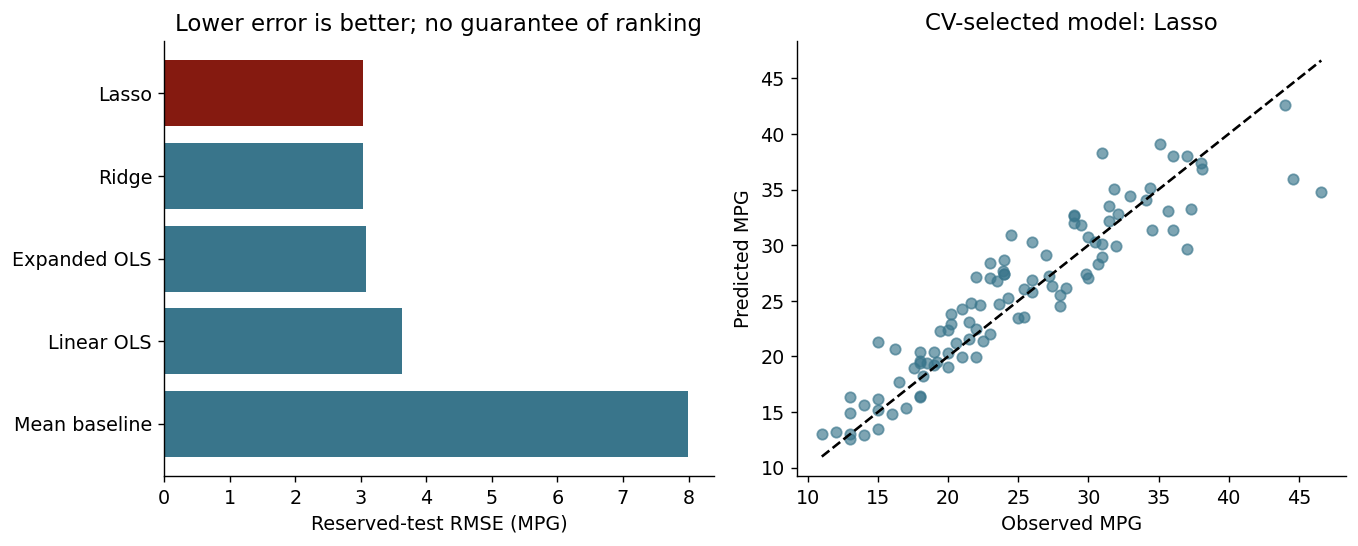

In [8]:
test_rows=[];predictions={}
for name,search in searches.items():
    pred=search.predict(X_test);predictions[name]=pred
    test_rows.append({'model':name,'selected_by_training_CV':name==winner,
      'test_n':len(y_test),'test_RMSE':np.sqrt(mean_squared_error(y_test,pred)),
      'test_MAE':mean_absolute_error(y_test,pred),'test_R2':r2_score(y_test,pred)})
test_results=pd.DataFrame(test_rows)
save_table(test_results,'fixed_test_comparison.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
axes[0].barh(test_results.model,test_results.test_RMSE,color=[BURGUNDY if n==winner else BLUE for n in test_results.model])
axes[0].set(xlabel='Reserved-test RMSE (MPG)',title='Lower error is better; no guarantee of ranking')
axes[1].scatter(y_test,predictions[winner],color=BLUE,alpha=.65)
lo=min(y_test.min(),predictions[winner].min());hi=max(y_test.max(),predictions[winner].max())
axes[1].plot([lo,hi],[lo,hi],color='black',linestyle='--')
axes[1].set(xlabel='Observed MPG',ylabel='Predicted MPG',title='CV-selected model: '+winner)
savefig('07_fixed_test_predictions.png')
pred_table=test[['record_id','car_name','mpg']].copy()
for name,pred in predictions.items():pred_table[name]=pred
pred_table.to_csv(OUT/'tables'/'test_predictions.csv',index=False)

**Checkpoint 6.** Compare the CV-selected model with the mean baseline. Describe both a useful improvement and a remaining limitation. Does Lasso outperform every other candidate on this split? What would change if the goal were 2027 vehicles, or a manufacturer unseen in training?

**Your answer:** ...

## 7. Connect the evidence to your individual research project · 6 minutes
Complete these sentences in your notebook:

1. My question asks for a **description / adjusted association / causal explanation / prediction** of ...
2. My outcome is ... measured in ... My unit of observation is ...
3. My proposed predictors and their literature-based reasons are ...
4. My intended specification or alternative method is ...
5. The most relevant threat is ... I will investigate it by ...
6. I will report an estimate and uncertainty / held-out prediction error / another appropriate evidence summary ...
7. My planned robustness check is ... It addresses ... but cannot address ...

Then write **80–120 words** summarizing one lab result. Include the question, sample, method, numeric evidence, and a justified claim boundary. For predictive work state how tuning and testing were separated. For OLS state that HC3 does not establish causality.

**Your project note:** ...

**Your result paragraph:** ...

**AI-use disclosure:** state whether you used AI, what it helped with, what you changed, and how you verified the result. Follow the instructor's assignment policy.

Qualitative or descriptive projects should choose evidence that fits their question. This lab does not impose a regression on every final project.

## 8. Export, restart, and save · 2 minutes
The bundle contains sources, sample flow, coefficient tables, diagnostics, CV results, test results, figures, and software versions. It does **not** automatically include your edited notebook: save or download that separately.

In [9]:
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'statsmodels':statsmodels.__version__,'scikit_learn':sklearn.__version__}
(OUT/'environment.json').write_text(json.dumps(versions,indent=2))
(OUT/'analysis_notes.txt').write_text(
    'Real UCI Auto MPG data, CC BY 4.0, DOI 10.24432/C5859H. Seed 1201 random 75/25 split.\n'
    'Complete training cases for explanatory OLS. Fold-specific median imputation for prediction.\n'
    'Five-fold shuffled training CV seed 1202. Selected model: '+winner+'\n'
    'HC3 assumes independent records. Similar vehicle models may be dependent. No causal claim.\n')
BUNDLE=Path(shutil.make_archive('W12_Regression_Outputs','zip',OUT))
print('Saved',BUNDLE.resolve())
print('Save your notebook separately. Restart and run all to verify reproducibility.')
# In Colab: use the folder icon to download the ZIP, or uncomment:
# from google.colab import files
# files.download(str(BUNDLE))

Saved C:\Users\vyshn\OneDrive - kdis.ac.kr\Documents\GitHub\Sogang\2026\Fall\Research Method of Data Science\W12\W12_Regression_Outputs.zip
Save your notebook separately. Restart and run all to verify reproducibility.


## 9. Optional extensions: choose according to your research aim
These cells are outside the 75-minute core. Running all is safe but creates additional outputs.

### 9A. Log outcomes and interactions
A log-MPG coefficient gives a proportional association. `100*(exp(b*change)-1)` is the exact percentage change in the fitted geometric outcome for that predictor change, holding other variables fixed. Simply exponentiating a log fit does not automatically recover expected arithmetic MPG.

An interaction lets the weight slope vary by model year. Centering both variables makes the main terms interpretable at 3,000 lb and year 1976. The interaction alone is not the full weight slope.

In [10]:
analysis['year_c']=analysis.model_year-76
logmod=smf.ols('np.log(mpg) ~ weight_1000 + horsepower + model_year + C(origin)',data=analysis).fit(cov_type='HC3',use_t=True)
interaction=smf.ols('mpg ~ weight_c * year_c + horsepower + C(origin)',data=analysis).fit(cov_type='HC3',use_t=True)
save_table(coef_table(logmod),'optional_log_OLS_HC3.csv')
save_table(coef_table(interaction),'optional_interaction_HC3.csv')
b=logmod.params['weight_1000']
print('A 1,000 lb change corresponds to',100*np.expm1(b),'percent change in fitted geometric MPG.')
print('Interaction local weight slopes by recorded year code:')
for year in [72,76,80]:
    slope=interaction.params['weight_c']+interaction.params['weight_c:year_c']*(year-76)
    print(year,round(slope,3),'MPG per 1,000 lb')

,term,estimate,SE,CI_low,CI_high,p_value
0,Intercept,1.593442,0.174543,1.249902,1.936983,1.247773e-17
1,C(origin)[T.2],0.071328,0.027293,0.017610,0.125047,9.433898e-03
2,C(origin)[T.3],0.050461,0.021379,0.008381,0.092540,1.892990e-02
3,weight_1000,-0.256445,0.019900,-0.295614,-0.217277,2.603824e-30
4,horsepower,-0.000770,0.000467,-0.001690,0.000151,1.008477e-01
5,model_year,0.030679,0.002115,0.026516,0.034843,3.686830e-36


,term,estimate,SE,CI_low,CI_high,p_value
0,Intercept,24.770980,1.034499,22.734813,26.807146,2.185371e-70
1,C(origin)[T.2],2.241831,0.790475,0.685966,3.797695,4.892425e-03
2,C(origin)[T.3],1.500694,0.593814,0.331912,2.669476,1.203432e-02
3,weight_c,-5.652040,0.433990,-6.506247,-4.797832,8.841023e-31
4,year_c,0.655304,0.055971,0.545138,0.765469,3.824663e-26
5,weight_c:year_c,-0.453468,0.075023,-0.601133,-0.305803,4.651247e-09
6,horsepower,-0.023322,0.009878,-0.042764,-0.003880,1.889304e-02


A 1,000 lb change corresponds to -22.620271639307145 percent change in fitted geometric MPG.
Interaction local weight slopes by recorded year code:
72 -3.838 MPG per 1,000 lb
76 -5.652 MPG per 1,000 lb
80 -7.466 MPG per 1,000 lb


### 9B. Elastic Net and Huber robust regression
Elastic Net combines L1 and L2 penalties. It can be useful with correlated features, but requires tuning. We evaluate it with training CV only here because the test set has already been opened. Its score cannot be compared as if it had an independent new test evaluation.

Huber robust regression downweights large residuals during fitting. It changes the estimator. HC3 changes uncertainty estimates while leaving OLS coefficients fixed. These solve different problems and neither fixes confounding.

In [11]:
enet=GridSearchCV(prediction_pipeline(ElasticNet(max_iter=100000,tol=1e-5)),
    {'model__alpha':np.logspace(-2,0,8),'model__l1_ratio':[.2,.5,.8]},
    cv=cv,scoring='neg_mean_squared_error',n_jobs=1,error_score='raise')
enet.fit(X_train,y_train)
print('Exploratory Elastic Net training CV RMSE:',np.sqrt(-enet.best_score_),'parameters:',enet.best_params_)
huber=smf.rlm(m3.model.formula,data=analysis,M=sm.robust.norms.HuberT()).fit()
robust_comparison=pd.DataFrame({'term':m3.model.exog_names,'OLS':np.asarray(m3.params),'Huber_RLM':np.asarray(huber.params)})
save_table(robust_comparison,'optional_Huber_comparison.csv')
# Refresh exported files after optional sections; no additional test evaluation.
shutil.make_archive('W12_Regression_Outputs','zip',OUT)

Exploratory Elastic Net training CV RMSE: 2.809009807370018 parameters: {'model__alpha': np.float64(0.01), 'model__l1_ratio': 0.8}


,term,OLS,Huber_RLM
0,Intercept,-38.048322,-33.811014
1,C(origin)[T.2],1.428302,0.566382
2,C(origin)[T.3],0.609180,0.768494
3,weight_c,-6.497487,-6.897929
4,I(weight_c ** 2),2.177271,2.097353
5,horsepower,-0.014529,-0.006111
6,model_year,0.803265,0.736248


'c:\\Users\\vyshn\\OneDrive - kdis.ac.kr\\Documents\\GitHub\\Sogang\\2026\\Fall\\Research Method of Data Science\\W12\\W12_Regression_Outputs.zip'

## Sources and interpretation safeguards
- Quinlan, R. (1993), *Auto MPG*, UCI Machine Learning Repository. https://doi.org/10.24432/C5859H . CC BY 4.0. Data copied unchanged, then parsed and transformed as documented above.
- ISLR2 authors, *Auto* documentation. https://search.r-project.org/CRAN/refmans/ISLR2/html/Auto.html . Units and teaching context.
- statsmodels, OLS HC3 covariance and regression diagnostics. https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.HC3_se.html and https://www.statsmodels.org/stable/examples/notebooks/generated/regression_diagnostics.html .
- scikit-learn, linear models and leakage guidance. https://scikit-learn.org/stable/modules/linear_model.html and https://scikit-learn.org/stable/common_pitfalls.html .

Records are historical and observational. Related car models and repeated names can violate a simple independent-record model. Random CV and the random test split are instructional approximations for similar records. Manufacturer-group or time-based validation would be needed for different deployment targets. The recorded variables omit aspects of design, technology, usage, and testing. Normality of X or Y is not an OLS requirement. Robust covariance and shrinkage do not remove these design limitations.